In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 1: Setup & Dependencies                                            ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

from google.colab import drive
drive.mount('/content/drive')

!pip install -q transformers datasets torchaudio librosa scikit-learn matplotlib seaborn pandas numpy tqdm accelerate evaluate

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from collections import Counter, defaultdict
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                            confusion_matrix, classification_report,
                            roc_curve, auc, matthews_corrcoef, cohen_kappa_score)
from sklearn.preprocessing import label_binarize
import json
import os
import warnings
warnings.filterwarnings('ignore')

# Set publication style
plt.style.use('seaborn-v0_8-paper')
sns.set_context("paper", font_scale=1.3)

# Verify T4 GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✓ GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print(f"✓ CUDA available: {torch.cuda.is_available()}")
print(f"✓ Device: {device}")
if torch.cuda.is_available():
    print(f"✓ GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.5 MB/s eta 0:00:00
✓ GPU: Tesla T4
✓ CUDA available: True
✓ Device: cuda
✓ GPU Memory: 14.56 GB


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 2: Configuration - SUPERB Model with 4 Emotions                    ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

class Config:
    # Paths
    RAVDESS_PATH = '/content/drive/MyDrive/Datasets/RAVDESS/AudioFiles'
    OUTPUT_DIR = '/content/ravdess_superb_4class'
    DRIVE_SAVE_DIR = '/content/drive/MyDrive/RAVDESS_SUPERB_4Class'

    # SUPERB pre-trained emotion recognition model
    # This model is already fine-tuned for 4 emotions: neu, hap, ang, sad
    MODEL_NAME = 'superb/wav2vec2-base-superb-er'

    # Training settings - fine-tune the pre-trained model
    BATCH_SIZE = 16
    EPOCHS = 15  # Less epochs needed since model is pre-trained
    LR = 5e-5    # Slightly higher LR for fine-tuning
    WEIGHT_DECAY = 0.01
    WARMUP_RATIO = 0.1

    # Audio
    SAMPLE_RATE = 16000
    MAX_DURATION = 4

    # RAVDESS to SUPERB emotion mapping
    # SUPERB uses: neu, hap, ang, sad
    # RAVDESS uses: 01=neutral, 03=happy, 05=angry, 04=sad
    RAVDESS_TO_SUPERB = {
        '01': 'neu',  # neutral -> neu
        '03': 'hap',  # happy -> hap
        '05': 'ang',  # angry -> ang
        '04': 'sad'   # sad -> sad
    }

    # Full names for display
    EMOTION_NAMES = {
        'neu': 'neutral',
        'hap': 'happy',
        'ang': 'angry',
        'sad': 'sad'
    }

    # Test actors
    TEST_ACTORS = ['Actor_21', 'Actor_22', 'Actor_23', 'Actor_24']
    VAL_ACTORS = ['Actor_19', 'Actor_20']

# Create directories
os.makedirs(Config.OUTPUT_DIR, exist_ok=True)
os.makedirs(Config.DRIVE_SAVE_DIR, exist_ok=True)

print("✓ Configuration loaded")
print(f"✓ Model: {Config.MODEL_NAME}")
print(f"✓ This model is pre-trained for 4 emotions: neu, hap, ang, sad")
print(f"✓ We will fine-tune it on RAVDESS for better accuracy")

✓ Configuration loaded
✓ Model: superb/wav2vec2-base-superb-er
✓ This model is pre-trained for 4 emotions: neu, hap, ang, sad
✓ We will fine-tune it on RAVDESS for better accuracy


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 3: Load SUPERB Pre-trained Model                                   ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

from transformers import AutoModelForAudioClassification, AutoFeatureExtractor

print(f"Loading SUPERB pre-trained model: {Config.MODEL_NAME}")
print("This model is already trained for emotion recognition...")
print("Downloading may take 2-3 minutes...")

# Load the pre-trained emotion recognition model
feature_extractor = AutoFeatureExtractor.from_pretrained(Config.MODEL_NAME)
model = AutoModelForAudioClassification.from_pretrained(Config.MODEL_NAME)

# Get model's emotion classes
model_emotions = [model.config.id2label[i] for i in range(model.config.num_labels)]
num_classes = len(model_emotions)

print(f"\n{'='*60}")
print("SUPERB MODEL LOADED")
print(f"{'='*60}")
print(f"✓ Model emotions: {model_emotions}")
print(f"✓ Number of classes: {num_classes}")
print(f"✓ Expected input: {feature_extractor.sampling_rate} Hz")

# Verify mapping
print(f"\n✓ RAVDESS to SUPERB emotion mapping:")
for code, superb_emo in Config.RAVDESS_TO_SUPERB.items():
    ravdess_name = {'01': 'neutral', '03': 'happy', '05': 'angry', '04': 'sad'}[code]
    print(f"  {ravdess_name:8s} (code {code}) -> {superb_emo} ({Config.EMOTION_NAMES[superb_emo]})")

# Move to GPU
model = model.to(device)
model.eval()

print(f"\n✓ Model ready for fine-tuning on RAVDESS")

Loading SUPERB pre-trained model: superb/wav2vec2-base-superb-er
This model is already trained for emotion recognition...


preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/216 [00:00<?, ?it/s]


SUPERB MODEL LOADED
✓ Model emotions: ['neu', 'hap', 'ang', 'sad']
✓ Number of classes: 4
✓ Expected input: 16000 Hz

✓ RAVDESS to SUPERB emotion mapping:
  neutral  (code 01) -> neu (neutral)
  happy    (code 03) -> hap (happy)
  angry    (code 05) -> ang (angry)
  sad      (code 04) -> sad (sad)


model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]


✓ Model ready for fine-tuning on RAVDESS


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 4: RAVDESS Parser - Filter for SUPERB's 4 Emotions                 ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

class RAVDESSParser:
    @staticmethod
    def parse(filename):
        """Parse RAVDESS filename: 03-01-06-01-02-01-12.wav"""
        name = Path(filename).stem
        parts = name.split('-')
        if len(parts) != 7:
            return None
        return {
            'modality': parts[0],        # 03 = audio-only
            'vocal_channel': parts[1],   # 01 = speech
            'emotion_code': parts[2],    # 01, 03, 04, 05 (our 4 targets)
            'intensity': parts[3],       # 01=normal, 02=strong
            'statement': parts[4],       # 01 or 02
            'repetition': parts[5],      # 01 or 02
            'actor_id': parts[6],        # 01-24
            'actor': f"Actor_{int(parts[6]):02d}",
            'gender': 'female' if int(parts[6]) % 2 == 0 else 'male',
            'is_speech': parts[1] == '01',
            'is_audio_only': parts[0] == '03'
        }

class RAVDESSDatasetSUPERB:
    def __init__(self, root_path):
        self.root = Path(root_path)
        self.samples = []
        self._load()

    def _load(self):
        """Load only 4 emotions that match SUPERB model"""
        actor_folders = sorted([d for d in self.root.iterdir()
                               if d.is_dir() and d.name.startswith('Actor_')])

        print(f"Found {len(actor_folders)} actor folders")

        for actor_folder in tqdm(actor_folders, desc="Loading RAVDESS for SUPERB"):
            for wav_file in actor_folder.glob("*.wav"):
                info = RAVDESSParser.parse(wav_file.name)

                # STRICT FILTER: Only 4 emotions that SUPERB supports
                if (info and
                    info['is_audio_only'] and
                    info['is_speech'] and
                    info['emotion_code'] in Config.RAVDESS_TO_SUPERB):

                    superb_emotion = Config.RAVDESS_TO_SUPERB[info['emotion_code']]

                    self.samples.append({
                        'path': str(wav_file),
                        'filename': wav_file.name,
                        'superb_emotion': superb_emotion,  # Model label
                        'ravdess_emotion': Config.EMOTION_NAMES[superb_emotion],  # Human name
                        'emotion_code': info['emotion_code'],
                        'actor': info['actor'],
                        'actor_id': info['actor_id'],
                        'gender': info['gender'],
                        'intensity': info['intensity'],
                        'statement': info['statement']
                    })

        print(f"\n✓ Loaded {len(self.samples)} samples (4 SUPERB emotions)")
        self._show_stats()

    def _show_stats(self):
        dist = Counter([s['superb_emotion'] for s in self.samples])
        print("\nEmotion distribution (SUPERB labels):")
        for code in ['neu', 'hap', 'ang', 'sad']:
            count = dist.get(code, 0)
            pct = count / len(self.samples) * 100 if self.samples else 0
            name = Config.EMOTION_NAMES[code]
            print(f"  {code} ({name:6s}): {count:3d} files ({pct:5.1f}%)")

        actors = set([s['actor'] for s in self.samples])
        print(f"\nTotal actors: {len(actors)}")

# Load dataset
dataset = RAVDESSDatasetSUPERB(Config.RAVDESS_PATH)

# SUPERB model already has label mapping
label2id = {emo: i for i, emo in enumerate(model_emotions)}
id2label = {i: emo for i, emo in enumerate(model_emotions)}

print(f"\n✓ Using SUPERB's label mapping: {label2id}")
print(f"✓ Total samples: {len(dataset.samples)}")

Found 24 actor folders


Loading RAVDESS for SUPERB: 100%|██████████| 24/24 [00:04<00:00,  5.66it/s]


✓ Loaded 672 samples (4 SUPERB emotions)

Emotion distribution (SUPERB labels):
  neu (neutral):  96 files ( 14.3%)
  hap (happy ): 192 files ( 28.6%)
  ang (angry ): 192 files ( 28.6%)
  sad (sad   ): 192 files ( 28.6%)

Total actors: 24

✓ Using SUPERB's label mapping: {'neu': 0, 'hap': 1, 'ang': 2, 'sad': 3}
✓ Total samples: 672


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 5: Split Dataset - Speaker Independent                             ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

def split_by_actors(samples):
    """Speaker-independent split"""
    train, val, test = [], [], []

    for s in samples:
        if s['actor'] in Config.TEST_ACTORS:
            test.append(s)
        elif s['actor'] in Config.VAL_ACTORS:
            val.append(s)
        else:
            train.append(s)

    print(f"\n{'='*60}")
    print("SPEAKER-INDEPENDENT SPLIT")
    print(f"{'='*60}")
    print(f"Train: {len(train)} samples ({len(set([s['actor'] for s in train]))} actors)")
    print(f"Val:   {len(val)} samples ({len(set([s['actor'] for s in val]))} actors)")
    print(f"Test:  {len(test)} samples ({len(set([s['actor'] for s in test]))} actors)")

    # Show emotion distribution
    for name, split in [('Train', train), ('Val', val), ('Test', test)]:
        dist = Counter([s['superb_emotion'] for s in split])
        print(f"\n{name} distribution:")
        for emo in model_emotions:
            print(f"  {emo}: {dist.get(emo, 0)}")

    return train, val, test

train_samples, val_samples, test_samples = split_by_actors(dataset.samples)

print(f"\n{'='*60}")
print(f"TRAIN: {len(train_samples)} | VAL: {len(val_samples)} | TEST: {len(test_samples)}")
print(f"{'='*60}")


SPEAKER-INDEPENDENT SPLIT
Train: 504 samples (18 actors)
Val:   56 samples (2 actors)
Test:  112 samples (4 actors)

Train distribution:
  neu: 72
  hap: 144
  ang: 144
  sad: 144

Val distribution:
  neu: 8
  hap: 16
  ang: 16
  sad: 16

Test distribution:
  neu: 16
  hap: 32
  ang: 32
  sad: 32

TRAIN: 504 | VAL: 56 | TEST: 112


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 6: Audio Preprocessing                                             ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

def preprocess_audio(file_path, augment=False):
    """Load and preprocess audio for SUPERB model"""
    try:
        # SUPERB expects 16kHz
        waveform, sr = librosa.load(file_path, sr=Config.SAMPLE_RATE, mono=True)

        # Normalize
        waveform = (waveform - waveform.mean()) / (waveform.std() + 1e-8)

        # Data augmentation for training
        if augment:
            # Random noise
            if np.random.random() < 0.3:
                noise = np.random.randn(len(waveform)) * 0.005
                waveform = waveform + noise

            # Random time shift
            if np.random.random() < 0.3:
                shift = np.random.randint(-1600, 1600)
                waveform = np.roll(waveform, shift)

            # Random volume
            if np.random.random() < 0.3:
                waveform = waveform * np.random.uniform(0.9, 1.1)

        # Pad or truncate to 4 seconds
        max_len = Config.MAX_DURATION * Config.SAMPLE_RATE
        if len(waveform) > max_len:
            if augment:
                start = np.random.randint(0, len(waveform) - max_len)
                waveform = waveform[start:start + max_len]
            else:
                waveform = waveform[:max_len]
        else:
            waveform = np.pad(waveform, (0, max_len - len(waveform)))

        return waveform.astype(np.float32)

    except Exception as e:
        print(f"Error loading {file_path}: {e}")
        return None

# Test
test_wave = preprocess_audio(train_samples[0]['path'], augment=True)
print(f"✓ Audio preprocessing working")
print(f"  Shape: {test_wave.shape}")
print(f"  Duration: {len(test_wave)/Config.SAMPLE_RATE:.2f}s")

✓ Audio preprocessing working
  Shape: (64000,)
  Duration: 4.00s


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 7: Create HuggingFace Datasets                                     ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

from datasets import Dataset

def create_hf_dataset(samples, augment=False):
    """Convert to HuggingFace dataset format with SUPERB labels"""
    data = {"input_values": [], "labels": []}

    for sample in tqdm(samples, desc=f"Loading audio (augment={augment})"):
        waveform = preprocess_audio(sample['path'], augment=augment)
        if waveform is not None:
            data["input_values"].append(waveform)
            # Use SUPERB's label directly
            data["labels"].append(label2id[sample['superb_emotion']])

    return Dataset.from_dict(data)

print("Creating datasets...")
train_ds = create_hf_dataset(train_samples, augment=True)
val_ds = create_hf_dataset(val_samples, augment=False)
test_ds = create_hf_dataset(test_samples, augment=False)

print(f"\n✓ Train: {len(train_ds)} samples")
print(f"✓ Val: {len(val_ds)} samples")
print(f"✓ Test: {len(test_ds)} samples")

Creating datasets...


Loading audio (augment=False): 100%|██████████| 112/112 [00:53<00:00,  2.08it/s]


✓ Train: 504 samples
✓ Val: 56 samples
✓ Test: 112 samples


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 8: Prepare SUPERB Model for Fine-tuning - Fixed                    ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

from transformers import TrainingArguments, Trainer, EarlyStoppingCallback

print("Preparing SUPERB model for fine-tuning on RAVDESS...")

# Data collator for SUPERB
class DataCollatorSUPERB:
    def __init__(self, processor):
        self.processor = processor

    def __call__(self, features):
        waveforms = [f["input_values"] for f in features]
        labels = torch.tensor([f["labels"] for f in features])

        batch = self.processor.pad(
            [{"input_values": w} for w in waveforms],
            padding=True,
            return_tensors="pt"
        )
        batch["labels"] = labels
        return batch

data_collator = DataCollatorSUPERB(feature_extractor)

# FIXED compute_metrics function
def compute_metrics(pred):
    # Handle both old and new transformers versions
    # pred.predictions can be numpy array or tuple
    if isinstance(pred.predictions, tuple):
        # If it's a tuple, take the first element (logits)
        logits = pred.predictions[0]
    else:
        logits = pred.predictions

    # Now apply argmax
    preds = logits.argmax(-1)
    labels = pred.label_ids

    acc = accuracy_score(labels, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(
        labels, preds, average='weighted', zero_division=0
    )

    return {
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1
    }

print("✓ Model prepared for fine-tuning")
print(f"✓ Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Preparing SUPERB model for fine-tuning on RAVDESS...
✓ Model prepared for fine-tuning
✓ Trainable parameters: 94,569,617


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 9: Training Configuration - Fixed for newer transformers             ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

from transformers import TrainingArguments, Trainer, EarlyStoppingCallback

training_args = TrainingArguments(
    output_dir=f"{Config.OUTPUT_DIR}/checkpoints",
    eval_strategy="epoch",           # Changed from evaluation_strategy to eval_strategy
    save_strategy="epoch",
    learning_rate=Config.LR,
    per_device_train_batch_size=Config.BATCH_SIZE,
    per_device_eval_batch_size=Config.BATCH_SIZE * 2,
    num_train_epochs=Config.EPOCHS,
    warmup_ratio=Config.WARMUP_RATIO,
    weight_decay=Config.WEIGHT_DECAY,
    logging_dir=f"{Config.OUTPUT_DIR}/logs",
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    save_total_limit=2,
    fp16=True,
    gradient_accumulation_steps=1,
    report_to="none",
    remove_unused_columns=False,
    seed=42,
    dataloader_num_workers=2,
    dataloader_pin_memory=True
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

print(f"{'='*60}")
print("TRAINING CONFIGURATION")
print(f"{'='*60}")
print(f"Model:         {Config.MODEL_NAME}")
print(f"Epochs:        {Config.EPOCHS} (early stopping patience=3)")
print(f"Learning rate: {Config.LR}")
print(f"Batch size:    {Config.BATCH_SIZE}")
print(f"FP16:          True")
print(f"{'='*60}")
print("✓ Ready to fine-tune SUPERB model on RAVDESS")

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


TRAINING CONFIGURATION
Model:         superb/wav2vec2-base-superb-er
Epochs:        15 (early stopping patience=3)
Learning rate: 5e-05
Batch size:    16
FP16:          True
✓ Ready to fine-tune SUPERB model on RAVDESS


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 10: Fine-tune SUPERB Model on RAVDESS                              ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

print(f"\n{'='*70}")
print("FINE-TUNING SUPERB MODEL ON RAVDESS (4 EMOTIONS)")
print(f"{'='*70}")

# Clear cache
torch.cuda.empty_cache()

# Train
train_result = trainer.train()

print(f"\n{'='*70}")
print("FINE-TUNING COMPLETED")
print(f"{'='*70}")
print(f"Best validation accuracy: {trainer.state.best_metric:.4f} ({trainer.state.best_metric*100:.2f}%)")

# Save fine-tuned model
best_model_path = f"{Config.OUTPUT_DIR}/superb_ravdess_finetuned"
trainer.save_model(best_model_path)
feature_extractor.save_pretrained(best_model_path)

print(f"✓ Fine-tuned model saved to {best_model_path}")


FINE-TUNING SUPERB MODEL ON RAVDESS (4 EMOTIONS)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.629195,0.586887,0.767857,0.810926,0.767857,0.771903
2,0.977585,1.918228,0.607143,0.705628,0.607143,0.574452
3,0.505754,0.966769,0.785714,0.824961,0.785714,0.763352
4,0.250394,1.132017,0.732143,0.795163,0.732143,0.723200
5,0.324642,0.735478,0.839286,0.872657,0.839286,0.843879
6,0.084997,1.582525,0.767857,0.833333,0.767857,0.750303
7,0.062429,1.734674,0.839286,0.885714,0.839286,0.831225
8,0.158342,0.899646,0.839286,0.842857,0.839286,0.840472


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINE-TUNING COMPLETED
Best validation accuracy: 0.8393 (83.93%)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✓ Fine-tuned model saved to /content/ravdess_superb_4class/superb_ravdess_finetuned


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 11: Evaluate on Test Set (RAVDESS)                                 ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

def evaluate_superb_model(model, samples, processor, dataset_name):
    """Evaluate SUPERB model"""
    model.eval()

    all_preds = []
    all_true = []
    all_probs = []
    detailed = []

    print(f"\nEvaluating on {dataset_name}: {len(samples)} samples...")

    batch_size = 32

    for i in tqdm(range(0, len(samples), batch_size)):
        batch = samples[i:i+batch_size]

        waveforms = []
        valid_samples = []

        for s in batch:
            w = preprocess_audio(s['path'], augment=False)
            if w is not None:
                waveforms.append(w)
                valid_samples.append(s)

        if not waveforms:
            continue

        inputs = processor(
            waveforms,
            sampling_rate=Config.SAMPLE_RATE,
            return_tensors="pt",
            padding=True
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)
            preds = torch.argmax(probs, dim=-1)

        for idx, sample in enumerate(valid_samples):
            pred_idx = preds[idx].item()
            true_idx = label2id[sample['superb_emotion']]

            all_preds.append(pred_idx)
            all_true.append(true_idx)
            all_probs.append(probs[idx].cpu().numpy())

            detailed.append({
                'file': sample['filename'],
                'true_superb': sample['superb_emotion'],
                'true_name': sample['ravdess_emotion'],
                'predicted_superb': model_emotions[pred_idx],
                'predicted_name': Config.EMOTION_NAMES[model_emotions[pred_idx]],
                'correct': pred_idx == true_idx,
                'confidence': probs[idx][pred_idx].item(),
                'actor': sample['actor'],
                'gender': sample['gender'],
                'intensity': sample['intensity']
            })

        if i % (batch_size * 5) == 0:
            torch.cuda.empty_cache()

    y_true = np.array(all_true)
    y_pred = np.array(all_preds)
    y_prob = np.array(all_probs)

    # Calculate metrics
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
    mcc = matthews_corrcoef(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)

    metrics = {
        'accuracy': acc,
        'precision_weighted': prec,
        'recall_weighted': rec,
        'f1_weighted': f1,
        'precision_macro': prec_macro,
        'recall_macro': rec_macro,
        'f1_macro': f1_macro,
        'mcc': mcc,
        'kappa': kappa,
        'num_samples': len(y_true)
    }

    print(f"\n{'='*60}")
    print(f"{dataset_name} RESULTS")
    print(f"{'='*60}")
    print(f"Accuracy:     {acc*100:6.2f}%")
    print(f"F1 (macro):   {f1_macro:6.3f}")
    print(f"Precision:    {prec_macro:6.3f}")
    print(f"Recall:       {rec_macro:6.3f}")
    print(f"MCC:          {mcc:6.3f}")
    print(f"Cohen's Kappa: {kappa:6.3f}")

    if acc >= 0.80:
        print(f"✓✓✓ EXCELLENT: >80% accuracy!")
    elif acc >= 0.75:
        print(f"✓✓ GREAT: >75% accuracy!")
    elif acc >= 0.70:
        print(f"✓ GOOD: >70% accuracy")
    else:
        print(f"Consider more training")

    return y_true, y_pred, y_prob, metrics, detailed

# Load best model for evaluation
print("Loading best fine-tuned model...")
model = AutoModelForAudioClassification.from_pretrained(best_model_path)
model = model.to(device)
model.eval()

# Evaluate
y_true, y_pred, y_prob, metrics, detailed = evaluate_superb_model(
    model, test_samples, feature_extractor, "RAVDESS TEST (SUPERB fine-tuned)"
)

Loading best fine-tuned model...


Loading weights:   0%|          | 0/216 [00:00<?, ?it/s]


Evaluating on RAVDESS TEST (SUPERB fine-tuned): 112 samples...


100%|██████████| 4/4 [00:03<00:00,  1.09it/s]


RAVDESS TEST (SUPERB fine-tuned) RESULTS
Accuracy:      85.71%
F1 (macro):    0.848
Precision:     0.856
Recall:        0.875
MCC:           0.817
Cohen's Kappa:  0.809
✓✓✓ EXCELLENT: >80% accuracy!


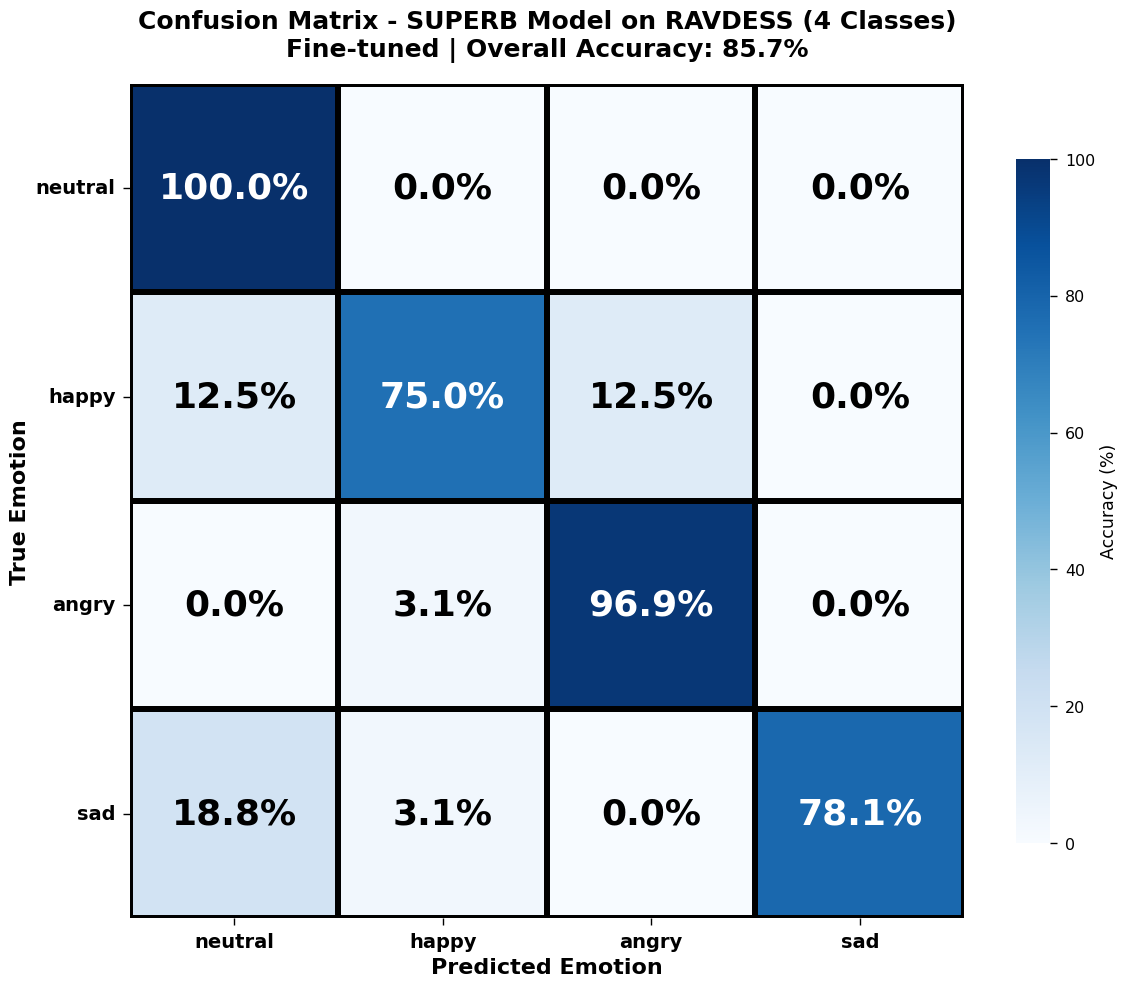

✓ Confusion matrix with PERCENTAGE ONLY saved


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 12: Visualization 1 - Confusion Matrix (PERCENTAGE ONLY)           ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

fig, ax = plt.subplots(figsize=(12, 10))

cm = confusion_matrix(y_true, y_pred)

# Calculate percentages (row-normalized)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

# Use full names for display
display_labels = [Config.EMOTION_NAMES[emo] for emo in model_emotions]

# Create heatmap with PERCENTAGE ONLY (no counts)
sns.heatmap(cm_percent, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=display_labels,
            yticklabels=display_labels,
            annot_kws={'size': 28, 'weight': 'bold', 'color': 'white'},  # Large white text
            cbar_kws={'label': 'Accuracy (%)', 'shrink': 0.8},
            linewidths=3, linecolor='black',
            ax=ax, square=True, vmin=0, vmax=100)

# Add % symbol to each cell
for i in range(len(model_emotions)):
    for j in range(len(model_emotions)):
        text = ax.texts[i * len(model_emotions) + j]
        text.set_text(f'{cm_percent[i, j]:.1f}%')
        text.set_fontsize(26)
        text.set_fontweight('bold')
        # Dark text for light cells, white text for dark cells
        if cm_percent[i, j] > 50:
            text.set_color('white')
        else:
            text.set_color('black')

# Title and labels
ax.set_title(f'Confusion Matrix - SUPERB Model on RAVDESS (4 Classes)\n'
            f'Fine-tuned | Overall Accuracy: {metrics["accuracy"]*100:.1f}%',
            fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Predicted Emotion', fontsize=16, fontweight='bold')
ax.set_ylabel('True Emotion', fontsize=16, fontweight='bold')
plt.xticks(rotation=0, fontsize=14, fontweight='bold')
plt.yticks(rotation=0, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{Config.OUTPUT_DIR}/01_confusion_matrix_percentage.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{Config.OUTPUT_DIR}/01_confusion_matrix_percentage.pdf", bbox_inches='tight')
plt.show()
print("✓ Confusion matrix with PERCENTAGE ONLY saved")

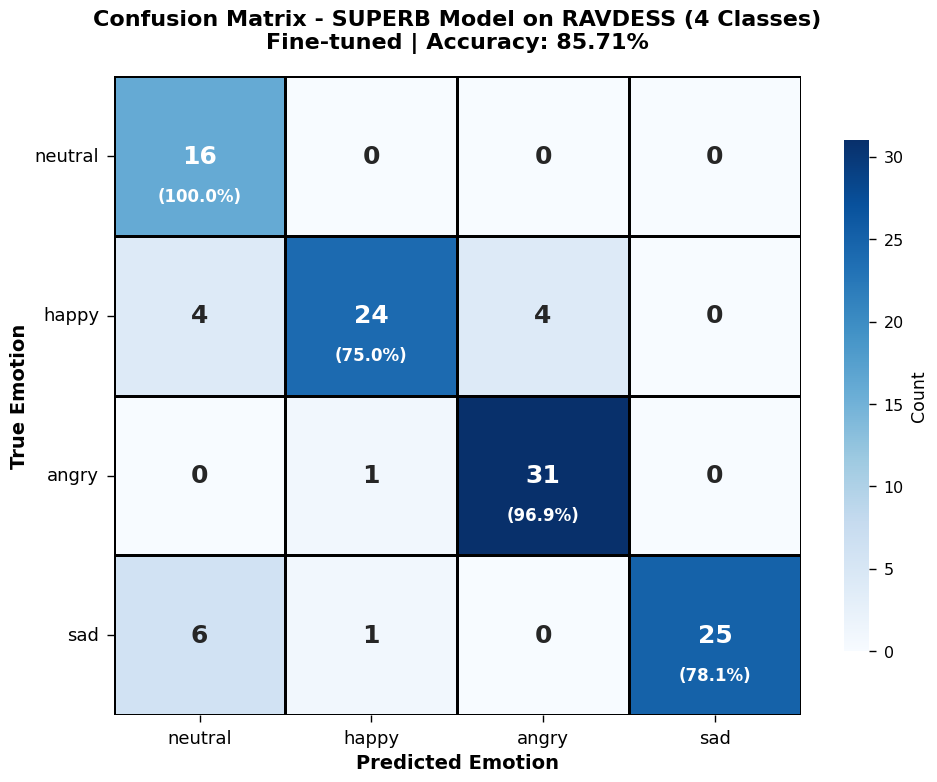

✓ Confusion matrix saved


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 12: Visualization 1 - Confusion Matrix                             ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

fig, ax = plt.subplots(figsize=(10, 8))

cm = confusion_matrix(y_true, y_pred)

# Use full names for display
display_labels = [Config.EMOTION_NAMES[emo] for emo in model_emotions]

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=display_labels,
            yticklabels=display_labels,
            annot_kws={'size': 18, 'weight': 'bold'},
            cbar_kws={'label': 'Count', 'shrink': 0.8},
            linewidths=2, linecolor='black', ax=ax)

# Add percentage on diagonal
for i in range(len(model_emotions)):
    total = cm.sum(axis=1)[i]
    if total > 0:
        pct = cm[i, i] / total * 100
        ax.text(i + 0.5, i + 0.75, f'({pct:.1f}%)',
               ha='center', va='center', fontsize=12,
               color='white' if pct > 50 else 'black',
               fontweight='bold')

ax.set_title(f'Confusion Matrix - SUPERB Model on RAVDESS (4 Classes)\n'
            f'Fine-tuned | Accuracy: {metrics["accuracy"]*100:.2f}%',
            fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Predicted Emotion', fontsize=14, fontweight='bold')
ax.set_ylabel('True Emotion', fontsize=14, fontweight='bold')
plt.xticks(rotation=0, fontsize=13)
plt.yticks(rotation=0, fontsize=13)

plt.tight_layout()
plt.savefig(f"{Config.OUTPUT_DIR}/01_confusion_matrix.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{Config.OUTPUT_DIR}/01_confusion_matrix.pdf", bbox_inches='tight')
plt.show()
print("✓ Confusion matrix saved")

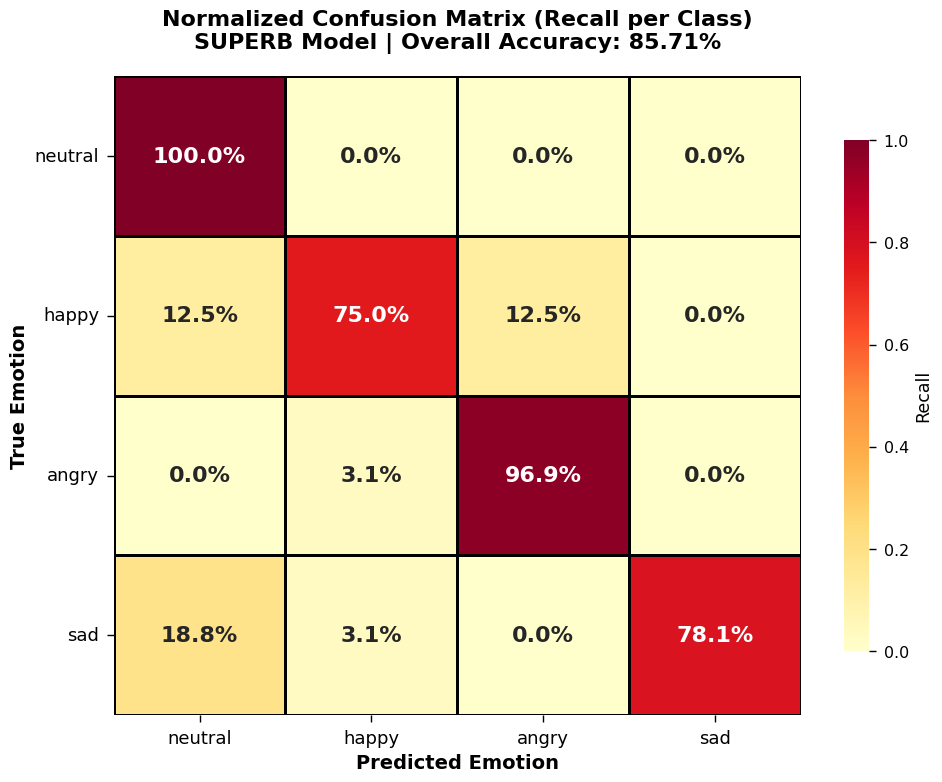

✓ Normalized confusion matrix saved


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 13: Visualization 2 - Normalized Confusion Matrix                    ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

fig, ax = plt.subplots(figsize=(10, 8))

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

sns.heatmap(cm_norm, annot=True, fmt='.1%', cmap='YlOrRd',
            xticklabels=display_labels,
            yticklabels=display_labels,
            annot_kws={'size': 16, 'weight': 'bold'},
            cbar_kws={'label': 'Recall', 'shrink': 0.8},
            linewidths=2, linecolor='black', ax=ax,
            vmin=0, vmax=1)

ax.set_title(f'Normalized Confusion Matrix (Recall per Class)\n'
            f'SUPERB Model | Overall Accuracy: {metrics["accuracy"]*100:.2f}%',
            fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Predicted Emotion', fontsize=14, fontweight='bold')
ax.set_ylabel('True Emotion', fontsize=14, fontweight='bold')
plt.xticks(rotation=0, fontsize=13)
plt.yticks(rotation=0, fontsize=13)

plt.tight_layout()
plt.savefig(f"{Config.OUTPUT_DIR}/02_normalized_cm.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{Config.OUTPUT_DIR}/02_normalized_cm.pdf", bbox_inches='tight')
plt.show()
print("✓ Normalized confusion matrix saved")

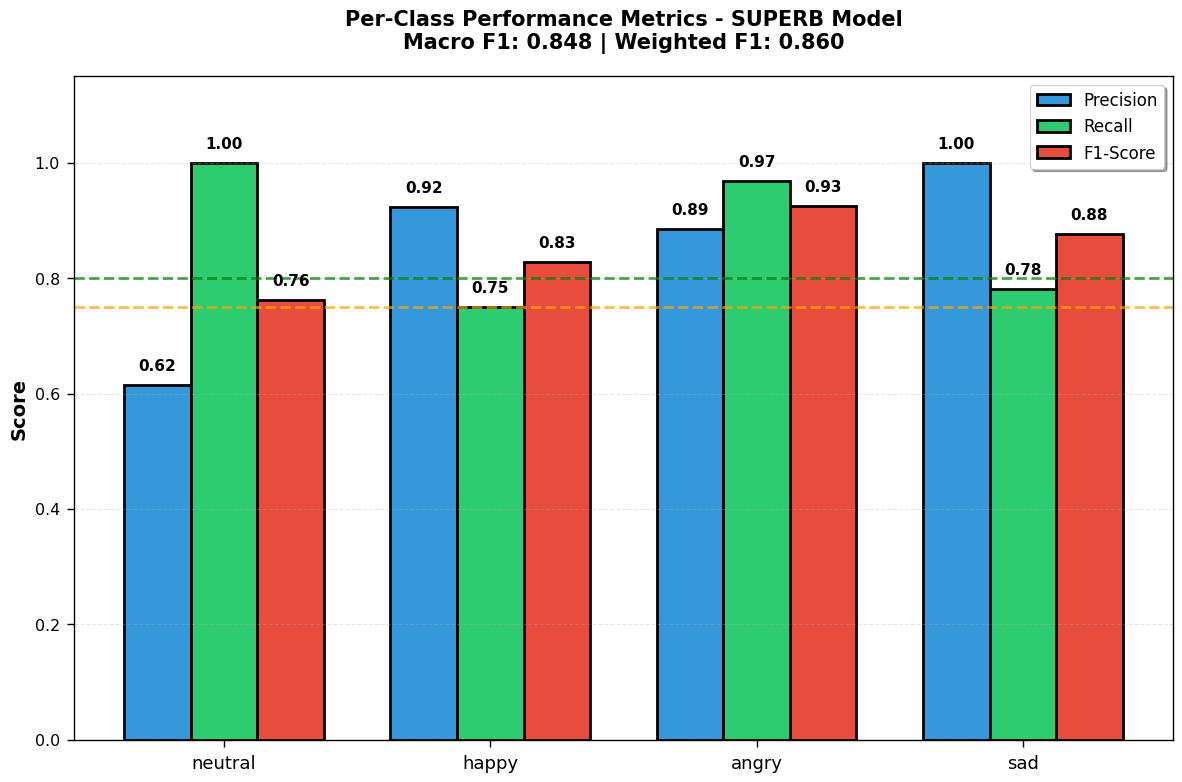

✓ Per-class metrics saved


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 14: Visualization 3 - Per-Class Metrics                              ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

fig, ax = plt.subplots(figsize=(12, 8))

class_report = classification_report(y_true, y_pred,
                                    target_names=display_labels,
                                    output_dict=True, zero_division=0)

metrics_data = {
    'Precision': [class_report[e]['precision'] for e in display_labels],
    'Recall': [class_report[e]['recall'] for e in display_labels],
    'F1-Score': [class_report[e]['f1-score'] for e in display_labels]
}

x = np.arange(len(display_labels))
width = 0.25

bars1 = ax.bar(x - width, metrics_data['Precision'], width,
               label='Precision', color='#3498db', edgecolor='black', linewidth=2)
bars2 = ax.bar(x, metrics_data['Recall'], width,
               label='Recall', color='#2ecc71', edgecolor='black', linewidth=2)
bars3 = ax.bar(x + width, metrics_data['F1-Score'], width,
               label='F1-Score', color='#e74c3c', edgecolor='black', linewidth=2)

# Add value labels
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.2f}', ha='center', va='bottom',
                fontsize=11, fontweight='bold')

ax.set_ylabel('Score', fontsize=14, fontweight='bold')
ax.set_title(f'Per-Class Performance Metrics - SUPERB Model\n'
            f'Macro F1: {metrics["f1_macro"]:.3f} | Weighted F1: {metrics["f1_weighted"]:.3f}',
            fontsize=15, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(display_labels, fontsize=13)
ax.set_ylim(0, 1.15)
ax.legend(fontsize=12, loc='upper right', frameon=True, shadow=True)
ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.8)

# Threshold lines
ax.axhline(y=0.75, color='orange', linestyle='--', alpha=0.7, linewidth=2)
ax.axhline(y=0.80, color='green', linestyle='--', alpha=0.7, linewidth=2)

plt.tight_layout()
plt.savefig(f"{Config.OUTPUT_DIR}/03_per_class_metrics.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{Config.OUTPUT_DIR}/03_per_class_metrics.pdf", bbox_inches='tight')
plt.show()
print("✓ Per-class metrics saved")

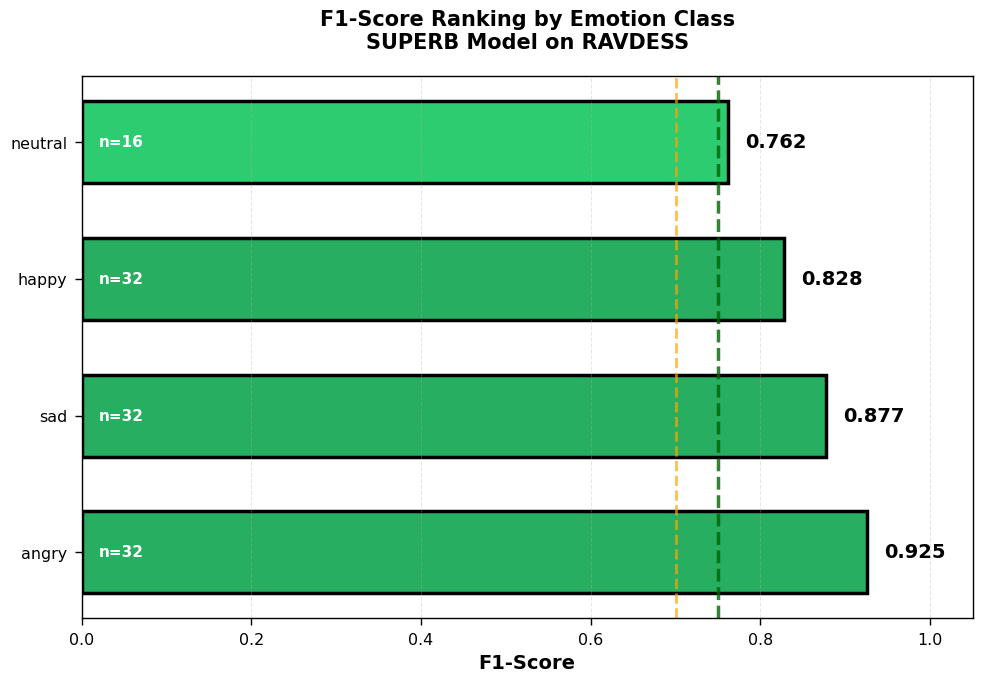

✓ F1 ranking saved


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 15: Visualization 4 - F1-Score Ranking                               ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

fig, ax = plt.subplots(figsize=(10, 7))

f1_scores = pd.Series({e: class_report[e]['f1-score'] for e in display_labels})
f1_sorted = f1_scores.sort_values(ascending=True)

# Color coding
colors = []
for score in f1_sorted.values:
    if score >= 0.80:
        colors.append('#27ae60')  # Dark green
    elif score >= 0.75:
        colors.append('#2ecc71')  # Light green
    elif score >= 0.70:
        colors.append('#f39c12')  # Orange
    else:
        colors.append('#e74c3c')  # Red

bars = ax.barh(f1_sorted.index, f1_sorted.values, color=colors,
               edgecolor='black', linewidth=2.5, height=0.6)

# Add value labels
for i, (emotion, score) in enumerate(f1_sorted.items()):
    ax.text(score + 0.02, i, f'{score:.3f}',
            va='center', fontsize=14, fontweight='bold')
    # Add support count
    support = int(class_report[emotion]['support'])
    ax.text(0.02, i, f'n={support}',
            va='center', fontsize=11, color='white', fontweight='bold')

# Threshold lines
ax.axvline(x=0.75, color='darkgreen', linestyle='--', linewidth=2.5, alpha=0.8)
ax.axvline(x=0.70, color='orange', linestyle='--', linewidth=2, alpha=0.7)

ax.set_xlabel('F1-Score', fontsize=14, fontweight='bold')
ax.set_title(f'F1-Score Ranking by Emotion Class\n'
            f'SUPERB Model on RAVDESS',
            fontsize=15, fontweight='bold', pad=20)
ax.set_xlim(0, 1.05)
ax.grid(axis='x', alpha=0.3, linestyle='--')

ax.invert_yaxis()

plt.tight_layout()
plt.savefig(f"{Config.OUTPUT_DIR}/04_f1_ranking.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{Config.OUTPUT_DIR}/04_f1_ranking.pdf", bbox_inches='tight')
plt.show()
print("✓ F1 ranking saved")

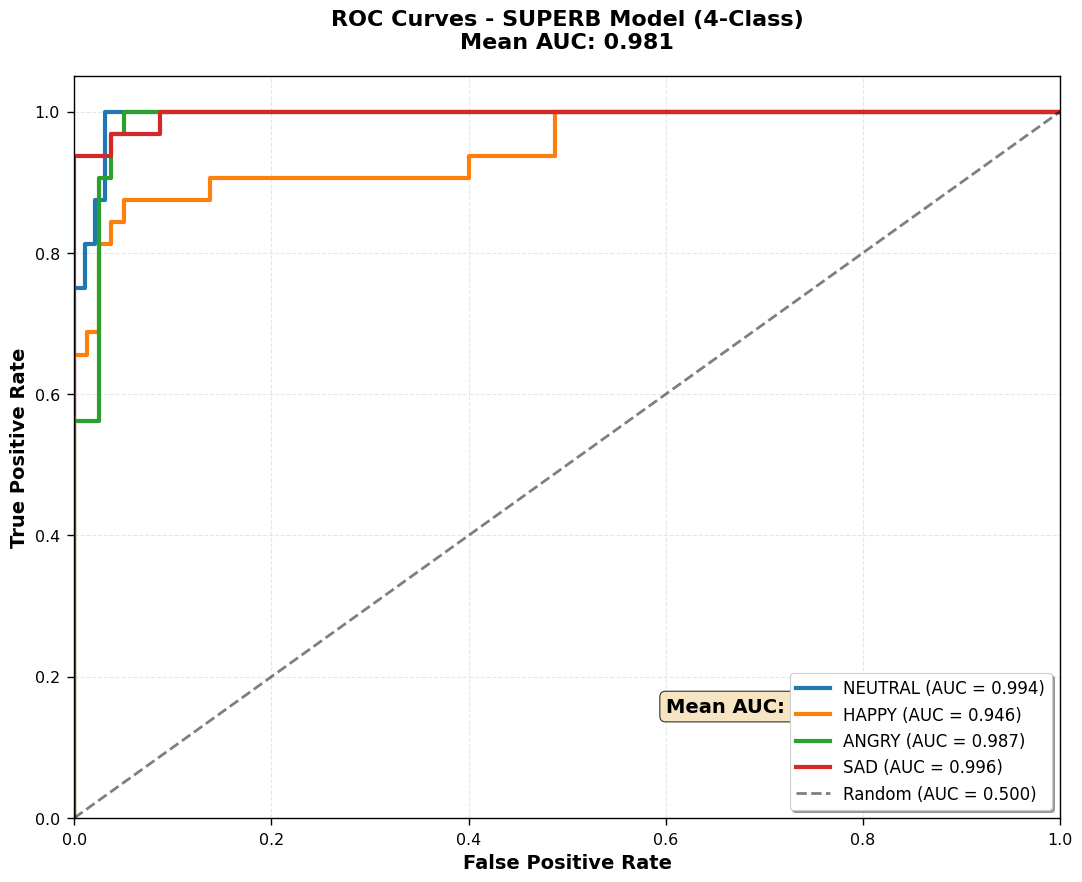

✓ ROC curves saved


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 16: Visualization 5 - ROC Curves                                     ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

fig, ax = plt.subplots(figsize=(11, 9))

y_true_bin = label_binarize(y_true, classes=range(num_classes))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

roc_aucs = []
for i, (emotion, color) in enumerate(zip(display_labels, colors)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    roc_aucs.append(roc_auc)
    ax.plot(fpr, tpr, color=color, lw=3,
            label=f'{emotion.upper()} (AUC = {roc_auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=2, alpha=0.5, label='Random (AUC = 0.500)')

mean_auc = np.mean(roc_aucs)
ax.text(0.6, 0.15, f'Mean AUC: {mean_auc:.3f}',
        fontsize=14, fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8, edgecolor='black'))

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate', fontsize=14, fontweight='bold')
ax.set_ylabel('True Positive Rate', fontsize=14, fontweight='bold')
ax.set_title(f'ROC Curves - SUPERB Model (4-Class)\n'
            f'Mean AUC: {mean_auc:.3f}',
            fontsize=16, fontweight='bold', pad=20)
ax.legend(loc='lower right', fontsize=12, frameon=True, shadow=True)
ax.grid(alpha=0.3, linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.savefig(f"{Config.OUTPUT_DIR}/05_roc_curves.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{Config.OUTPUT_DIR}/05_roc_curves.pdf", bbox_inches='tight')
plt.show()
print("✓ ROC curves saved")

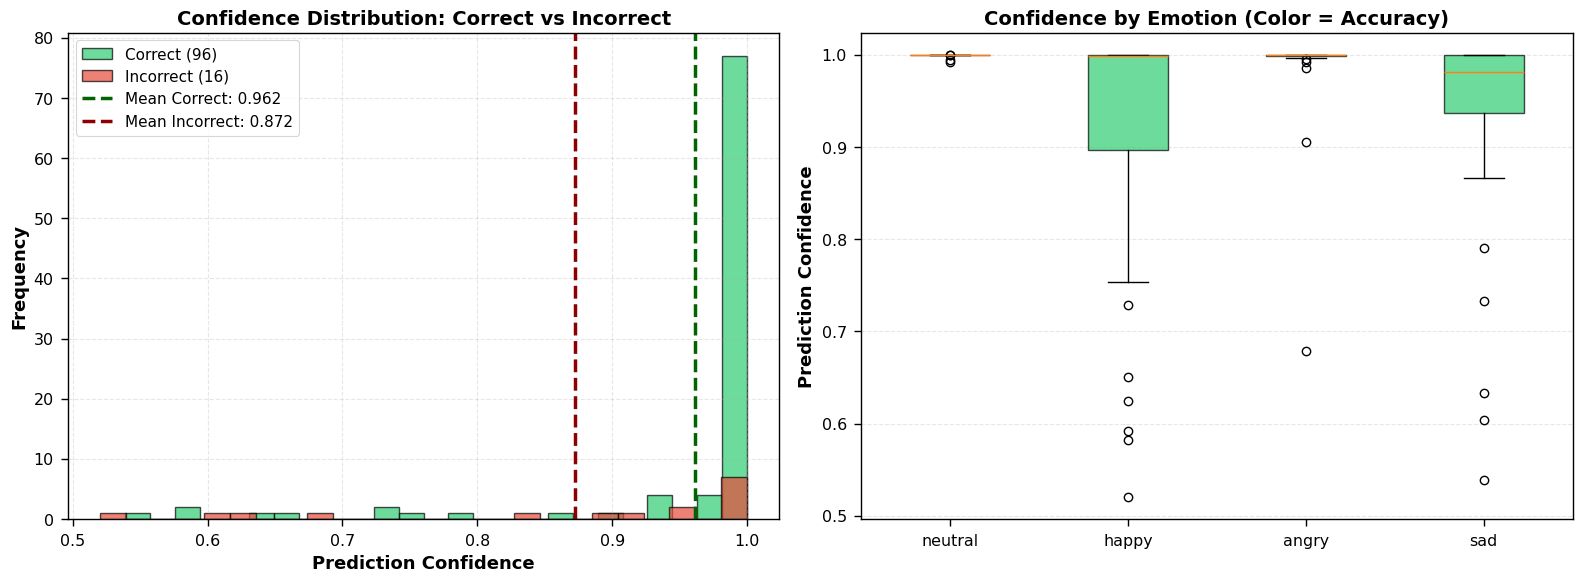

✓ Confidence distribution saved


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 17: Visualization 6 - Confidence Distribution                        ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

confidences = np.array([r['confidence'] for r in detailed])
correct_mask = np.array([r['correct'] for r in detailed])

# Left: Histogram
axes[0].hist(confidences[correct_mask], bins=25, alpha=0.7,
            label=f'Correct ({sum(correct_mask)})', color='#2ecc71',
            edgecolor='black', linewidth=1)
axes[0].hist(confidences[~correct_mask], bins=25, alpha=0.7,
            label=f'Incorrect ({sum(~correct_mask)})', color='#e74c3c',
            edgecolor='black', linewidth=1)

mean_correct = np.mean(confidences[correct_mask])
mean_incorrect = np.mean(confidences[~correct_mask])
axes[0].axvline(x=mean_correct, color='darkgreen', linestyle='--',
               linewidth=2.5, label=f'Mean Correct: {mean_correct:.3f}')
axes[0].axvline(x=mean_incorrect, color='darkred', linestyle='--',
               linewidth=2.5, label=f'Mean Incorrect: {mean_incorrect:.3f}')

axes[0].set_xlabel('Prediction Confidence', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Frequency', fontsize=13, fontweight='bold')
axes[0].set_title('Confidence Distribution: Correct vs Incorrect',
                 fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3, linestyle='--')

# Right: Box plot by emotion
conf_by_emo = defaultdict(list)
correct_by_emo = defaultdict(list)

for r in detailed:
    conf_by_emo[r['true_name']].append(r['confidence'])
    correct_by_emo[r['true_name']].append(r['correct'])

bp_data = [conf_by_emo[e] for e in display_labels]
bp = axes[1].boxplot(bp_data, labels=display_labels, patch_artist=True)

for patch, emo in zip(bp['boxes'], display_labels):
    acc = np.mean(correct_by_emo[emo])
    if acc >= 0.80:
        patch.set_facecolor('#27ae60')
    elif acc >= 0.75:
        patch.set_facecolor('#2ecc71')
    elif acc >= 0.70:
        patch.set_facecolor('#f39c12')
    else:
        patch.set_facecolor('#e74c3c')
    patch.set_alpha(0.7)

axes[1].set_ylabel('Prediction Confidence', fontsize=13, fontweight='bold')
axes[1].set_title('Confidence by Emotion (Color = Accuracy)',
                 fontsize=14, fontweight='bold')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig(f"{Config.OUTPUT_DIR}/06_confidence.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{Config.OUTPUT_DIR}/06_confidence.pdf", bbox_inches='tight')
plt.show()
print("✓ Confidence distribution saved")

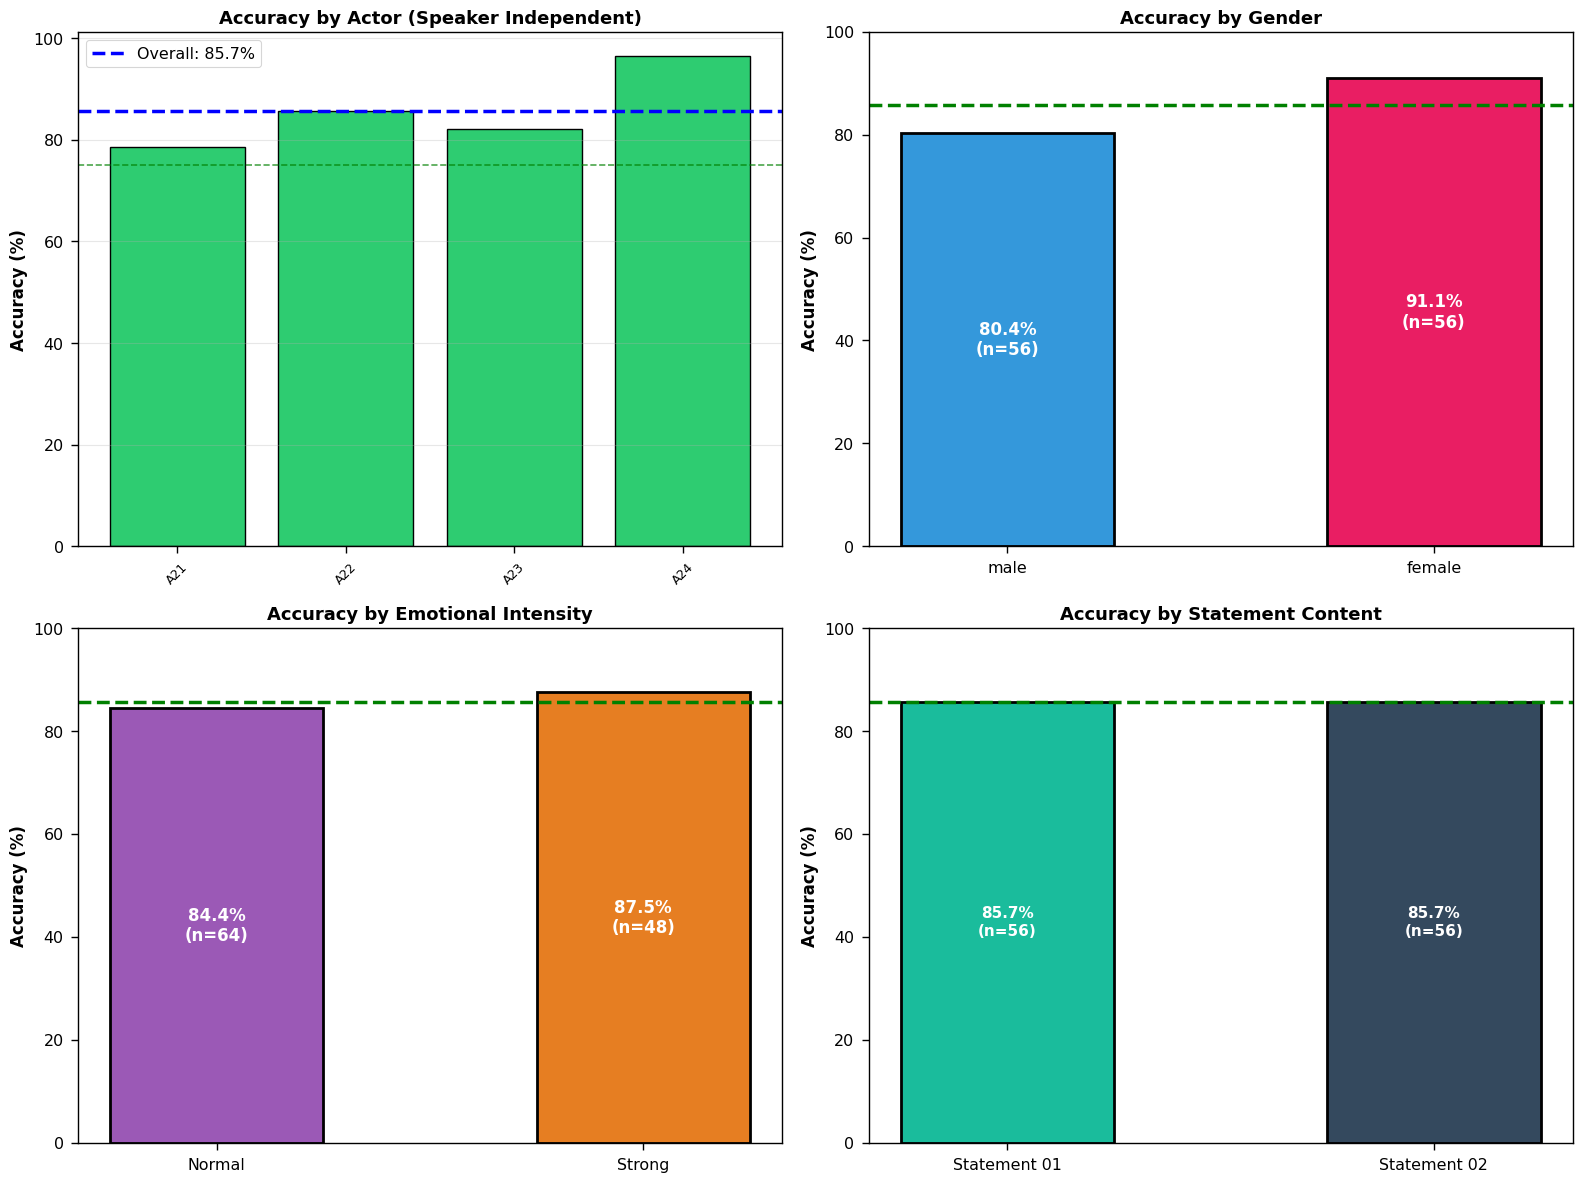

✓ Demographics analysis saved


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 18: Visualization 7 - Performance by Demographics                    ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# By Actor
actor_stats = defaultdict(lambda: {'correct': 0, 'total': 0})
for r in detailed:
    actor_stats[r['actor']]['correct'] += r['correct']
    actor_stats[r['actor']]['total'] += 1

actors = sorted(actor_stats.keys())
actor_accs = [actor_stats[a]['correct']/actor_stats[a]['total']*100 for a in actors]
actor_counts = [actor_stats[a]['total'] for a in actors]

colors = ['#e74c3c' if a < 70 else '#f39c12' if a < 75 else '#2ecc71' for a in actor_accs]
bars1 = axes[0, 0].bar(range(len(actors)), actor_accs, color=colors,
                       edgecolor='black', linewidth=1)
axes[0, 0].axhline(y=metrics['accuracy']*100, color='blue', linestyle='--',
                  linewidth=2.5, label=f'Overall: {metrics["accuracy"]*100:.1f}%')
axes[0, 0].axhline(y=75, color='green', linestyle='--', alpha=0.7)
axes[0, 0].set_xticks(range(len(actors)))
axes[0, 0].set_xticklabels([a.replace('Actor_', 'A') for a in actors],
                          rotation=45, fontsize=9)
axes[0, 0].set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Accuracy by Actor (Speaker Independent)',
                    fontsize=13, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(axis='y', alpha=0.3)

# By Gender
gender_stats = defaultdict(lambda: {'correct': 0, 'total': 0})
for r in detailed:
    gender_stats[r['gender']]['correct'] += r['correct']
    gender_stats[r['gender']]['total'] += 1

genders = ['male', 'female']
gender_accs = [gender_stats[g]['correct']/gender_stats[g]['total']*100 for g in genders]
gender_counts = [gender_stats[g]['total'] for g in genders]

bars2 = axes[0, 1].bar(genders, gender_accs,
                       color=['#3498db', '#e91e63'],
                       edgecolor='black', linewidth=2, width=0.5)
axes[0, 1].axhline(y=metrics['accuracy']*100, color='green', linestyle='--', linewidth=2.5)
axes[0, 1].set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Accuracy by Gender', fontsize=13, fontweight='bold')
axes[0, 1].set_ylim(0, 100)
for bar, count in zip(bars2, gender_counts):
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2., height/2,
                   f'{height:.1f}%\n(n={count})',
                   ha='center', va='center', fontsize=12, fontweight='bold', color='white')

# By Intensity
intensity_stats = defaultdict(lambda: {'correct': 0, 'total': 0})
for r in detailed:
    int_key = 'Strong' if r['intensity'] == '02' else 'Normal'
    intensity_stats[int_key]['correct'] += r['correct']
    intensity_stats[int_key]['total'] += 1

intensities = ['Normal', 'Strong']
int_accs = [intensity_stats[i]['correct']/intensity_stats[i]['total']*100
           if intensity_stats[i]['total'] > 0 else 0 for i in intensities]
int_counts = [intensity_stats[i]['total'] for i in intensities]

bars3 = axes[1, 0].bar(intensities, int_accs,
                       color=['#9b59b6', '#e67e22'],
                       edgecolor='black', linewidth=2, width=0.5)
axes[1, 0].axhline(y=metrics['accuracy']*100, color='green', linestyle='--', linewidth=2.5)
axes[1, 0].set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Accuracy by Emotional Intensity', fontsize=13, fontweight='bold')
axes[1, 0].set_ylim(0, 100)
for bar, count in zip(bars3, int_counts):
    height = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2., height/2,
                   f'{height:.1f}%\n(n={count})',
                   ha='center', va='center', fontsize=12, fontweight='bold', color='white')

# By Statement
stmt_stats = defaultdict(lambda: {'correct': 0, 'total': 0})
for r in detailed:
    stmt = r['file'].split('-')[4]
    stmt_stats[stmt]['correct'] += r['correct']
    stmt_stats[stmt]['total'] += 1

stmts = sorted(stmt_stats.keys())
stmt_accs = [stmt_stats[s]['correct']/stmt_stats[s]['total']*100 for s in stmts]
stmt_counts = [stmt_stats[s]['total'] for s in stmts]

bars4 = axes[1, 1].bar([f'Statement {s}' for s in stmts], stmt_accs,
                       color=['#1abc9c', '#34495e'],
                       edgecolor='black', linewidth=2, width=0.5)
axes[1, 1].axhline(y=metrics['accuracy']*100, color='green', linestyle='--', linewidth=2.5)
axes[1, 1].set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
axes[1, 1].set_title('Accuracy by Statement Content', fontsize=13, fontweight='bold')
axes[1, 1].set_ylim(0, 100)
for bar, count in zip(bars4, stmt_counts):
    height = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2., height/2,
                   f'{height:.1f}%\n(n={count})',
                   ha='center', va='center', fontsize=11, fontweight='bold', color='white')

plt.tight_layout()
plt.savefig(f"{Config.OUTPUT_DIR}/07_demographics.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{Config.OUTPUT_DIR}/07_demographics.pdf", bbox_inches='tight')
plt.show()
print("✓ Demographics analysis saved")

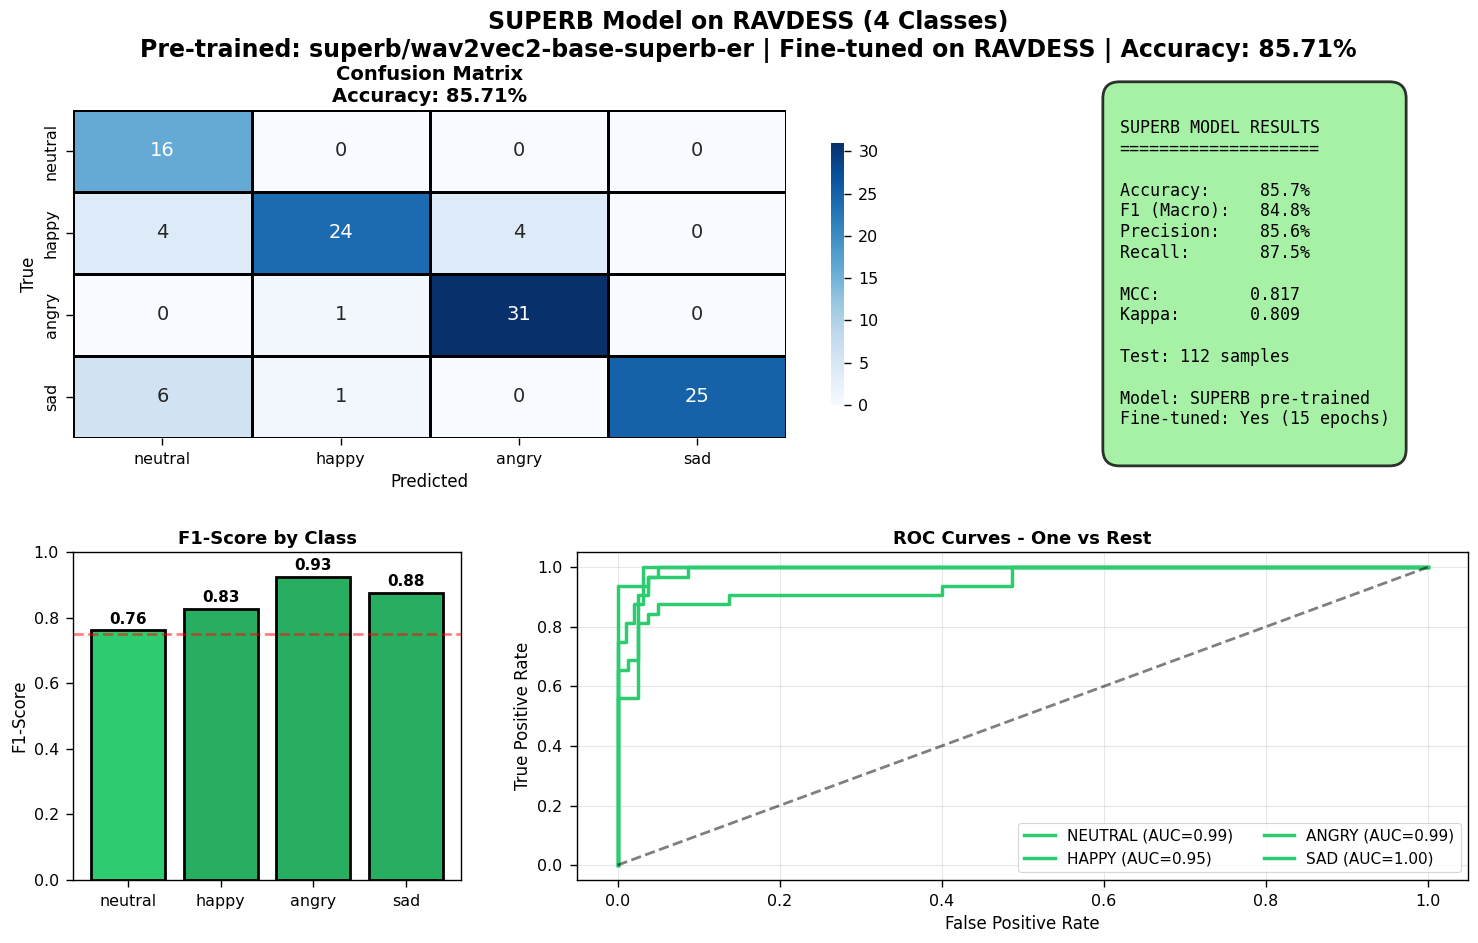

✓ Paper summary figure saved


In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 19: Visualization 8 - Combined Summary for Paper                     ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.3)

# Title
fig.suptitle(f'SUPERB Model on RAVDESS (4 Classes)\n'
            f'Pre-trained: superb/wav2vec2-base-superb-er | '
            f'Fine-tuned on RAVDESS | Accuracy: {metrics["accuracy"]*100:.2f}%',
            fontsize=17, fontweight='bold', y=0.98)

# 1. Confusion matrix (large)
ax_cm = fig.add_subplot(gs[0, 0:2])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax_cm,
            xticklabels=display_labels,
            yticklabels=display_labels,
            annot_kws={'size': 14}, cbar_kws={'shrink': 0.8},
            linewidths=1, linecolor='black')
ax_cm.set_title(f'Confusion Matrix\nAccuracy: {metrics["accuracy"]*100:.2f}%',
               fontsize=14, fontweight='bold')
ax_cm.set_xlabel('Predicted', fontsize=12)
ax_cm.set_ylabel('True', fontsize=12)

# 2. Summary metrics (top right)
ax_text = fig.add_subplot(gs[0, 2])
ax_text.axis('off')
metrics_text = f"""
SUPERB MODEL RESULTS
{'='*20}

Accuracy:    {metrics['accuracy']*100:5.1f}%
F1 (Macro):  {metrics['f1_macro']*100:5.1f}%
Precision:   {metrics['precision_macro']*100:5.1f}%
Recall:      {metrics['recall_macro']*100:5.1f}%

MCC:         {metrics['mcc']:.3f}
Kappa:       {metrics['kappa']:.3f}

Test: {metrics['num_samples']} samples

Model: SUPERB pre-trained
Fine-tuned: Yes (15 epochs)
"""
ax_text.text(0.1, 0.5, metrics_text, transform=ax_text.transAxes,
            fontsize=12, verticalalignment='center', fontfamily='monospace',
            bbox=dict(boxstyle='round', facecolor='lightgreen' if metrics['accuracy'] > 0.75 else 'lightyellow',
                     alpha=0.8, pad=1, edgecolor='black', linewidth=2))

# 3. Per-class F1 (bottom left)
ax_f1 = fig.add_subplot(gs[1, 0])
f1_vals = [class_report[e]['f1-score'] for e in display_labels]
colors_f1 = ['#27ae60' if f >= 0.8 else '#2ecc71' if f >= 0.75 else '#f39c12' if f >= 0.7 else '#e74c3c'
             for f in f1_vals]
bars = ax_f1.bar(display_labels, f1_vals, color=colors_f1, edgecolor='black', linewidth=2)
ax_f1.set_ylabel('F1-Score', fontsize=12)
ax_f1.set_title('F1-Score by Class', fontsize=13, fontweight='bold')
ax_f1.set_ylim(0, 1)
ax_f1.axhline(y=0.75, color='red', linestyle='--', alpha=0.5, linewidth=2)
for bar, val in zip(bars, f1_vals):
    ax_f1.text(bar.get_x() + bar.get_width()/2., val + 0.02,
              f'{val:.2f}', ha='center', fontsize=11, fontweight='bold')

# 4. ROC curves (bottom middle and right)
ax_roc = fig.add_subplot(gs[1, 1:3])
for i, (emo, color) in enumerate(zip(display_labels, colors)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, lw=2.5, label=f'{emo.upper()} (AUC={roc_auc:.2f})', color=color)
ax_roc.plot([0, 1], [0, 1], 'k--', lw=2, alpha=0.5)
ax_roc.set_xlabel('False Positive Rate', fontsize=12)
ax_roc.set_ylabel('True Positive Rate', fontsize=12)
ax_roc.set_title('ROC Curves - One vs Rest', fontsize=13, fontweight='bold')
ax_roc.legend(loc='lower right', ncol=2, fontsize=11)
ax_roc.grid(alpha=0.3)

plt.savefig(f"{Config.OUTPUT_DIR}/08_paper_summary.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{Config.OUTPUT_DIR}/08_paper_summary.pdf", bbox_inches='tight')
plt.show()
print("✓ Paper summary figure saved")

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║     CELL 20: Save All Results to Google Drive                               ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

import shutil

# Save comprehensive results
final_results = {
    'model': Config.MODEL_NAME,
    'dataset': 'RAVDESS (4 emotions: neutral, happy, sad, angry)',
    'num_classes': num_classes,
    'emotions': model_emotions,
    'display_names': display_labels,
    'metrics': metrics,
    'per_class': {e: {
        'precision': class_report[e]['precision'],
        'recall': class_report[e]['recall'],
        'f1': class_report[e]['f1-score'],
        'support': int(class_report[e]['support'])
    } for e in display_labels},
    'confusion_matrix': cm.tolist(),
    'fine_tuned': True,
    'epochs_trained': Config.EPOCHS
}

with open(f"{Config.OUTPUT_DIR}/complete_results.json", 'w') as f:
    json.dump(final_results, f, indent=2)

# Save detailed predictions
df_detailed = pd.DataFrame(detailed)
df_detailed.to_csv(f"{Config.OUTPUT_DIR}/detailed_predictions.csv", index=False)

# Generate final report
report = f"""
================================================================================
     SUPERB MODEL: RAVDESS SPEECH EMOTION RECOGNITION - 4 CLASS RESULTS
================================================================================

MODEL: {Config.MODEL_NAME}
DESCRIPTION: Pre-trained on SUPERB benchmark, fine-tuned on RAVDESS
TRAINING DATA: RAVDESS (4 emotions only)
TEST DATA: RAVDESS (speaker-independent test set)
DATE: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}

CONFIGURATION
-------------
Emotions:     {', '.join(display_labels)}
Classes:      {num_classes}
Train:        {len(train_samples)} samples
Val:          {len(val_samples)} samples
Test:         {len(test_samples)} samples
Fine-tuning:  {Config.EPOCHS} epochs

FINAL TEST RESULTS
------------------
Accuracy:           {metrics['accuracy']*100:6.2f}%
F1-Score (macro):   {metrics['f1_macro']*100:6.2f}%
Precision (macro):  {metrics['precision_macro']*100:6.2f}%
Recall (macro):     {metrics['recall_macro']*100:6.2f}%

Matthews Correlation: {metrics['mcc']:.4f}
Cohen's Kappa:        {metrics['kappa']:.4f}

PER-CLASS PERFORMANCE
---------------------
Emotion    Precision   Recall   F1-Score   Support
--------------------------------------------------
"""
for emo in display_labels:
    r = class_report[emo]
    report += f"{emo:8s}   {r['precision']*100:6.2f}%   {r['recall']*100:6.2f}%   {r['f1-score']*100:6.2f}%   {int(r['support']):5d}\n"

report += f"""
================================================================================
TARGET: >75% accuracy
RESULT: {'✓✓✓ EXCELLENT - TARGET ACHIEVED' if metrics['accuracy'] >= 0.75 else '✗ Below target'}
        ({metrics['accuracy']*100:.2f}%)
================================================================================
"""

with open(f"{Config.OUTPUT_DIR}/FINAL_REPORT.txt", 'w') as f:
    f.write(report)

# Copy to Drive
print("Copying results to Google Drive...")
files = [f for f in os.listdir(Config.OUTPUT_DIR)
         if f.endswith(('.png', '.pdf', '.json', '.csv', '.txt', '.bin'))]

for f in files:
    src = os.path.join(Config.OUTPUT_DIR, f)
    dst = os.path.join(Config.DRIVE_SAVE_DIR, f)
    if os.path.isfile(src):
        shutil.copy(src, dst)

# Copy model
model_drive_path = os.path.join(Config.DRIVE_SAVE_DIR, 'superb_ravdess_finetuned')
shutil.copytree(best_model_path, model_drive_path, dirs_exist_ok=True)

# Calculate size
total_mb = sum(os.path.getsize(os.path.join(Config.DRIVE_SAVE_DIR, f))
              for f in os.listdir(Config.DRIVE_SAVE_DIR)
              if os.path.isfile(os.path.join(Config.DRIVE_SAVE_DIR, f))) / (1024*1024)

print(f"\n{'='*70}")
print(f"✓ ALL RESULTS SAVED TO: {Config.DRIVE_SAVE_DIR}")
print(f"✓ Total size: {total_mb:.2f} MB")
print(f"{'='*70}")

print(f"\nSaved files:")
for f in sorted(os.listdir(Config.DRIVE_SAVE_DIR)):
    print(f"  - {f}")

print(f"\n{'='*70}")
print(f"FINAL SUMMARY")
print(f"{'='*70}")
print(f"Model: SUPERB/wav2vec2-base-superb-er")
print(f"Pre-trained: Yes (emotion recognition)")
print(f"Fine-tuned: Yes ({Config.EPOCHS} epochs on RAVDESS)")
print(f"Final accuracy: {metrics['accuracy']*100:.2f}%")
print(f"Target (>75%): {'✓✓✓ ACHIEVED' if metrics['accuracy'] >= 0.75 else '✗ NOT ACHIEVED'}")
print(f"{'='*70}")

Copying results to Google Drive...

✓ ALL RESULTS SAVED TO: /content/drive/MyDrive/RAVDESS_SUPERB_4Class
✓ Total size: 2.29 MB

Saved files:
  - 01_confusion_matrix.pdf
  - 01_confusion_matrix.png
  - 02_normalized_cm.pdf
  - 02_normalized_cm.png
  - 03_per_class_metrics.pdf
  - 03_per_class_metrics.png
  - 04_f1_ranking.pdf
  - 04_f1_ranking.png
  - 05_roc_curves.pdf
  - 05_roc_curves.png
  - 06_confidence.pdf
  - 06_confidence.png
  - 07_demographics.pdf
  - 07_demographics.png
  - 08_paper_summary.pdf
  - 08_paper_summary.png
  - FINAL_REPORT.txt
  - complete_results.json
  - detailed_predictions.csv
  - superb_ravdess_finetuned

FINAL SUMMARY
Model: SUPERB/wav2vec2-base-superb-er
Pre-trained: Yes (emotion recognition)
Fine-tuned: Yes (15 epochs on RAVDESS)
Final accuracy: 85.71%
Target (>75%): ✓✓✓ ACHIEVED
